DAY 13: RAYLEIGH NUMBER AND HEAT TRANSPORT
Reading: C:\Users\athil\OneDrive\Desktop\combined_mantle_results_2\combined_summary.csv

Data loaded successfully.
Number of unique Rayleigh numbers: 4

RESULTS
----------------------------------------------------------------------------
        Ra      Nu bottom         Nu top      Max speed     Mismatch %
----------------------------------------------------------------------------
    500.00       7.053559       7.651112     133.097571          7.810
   1000.00       5.836153       7.763582     260.192972         24.827
   2500.00       9.746132      12.454052     488.319346         21.743
   5000.00      13.927691      14.250779     795.557041          2.267

Saved analysis table: day13_Ra_Nu_analysis\day13_analysis_table.csv


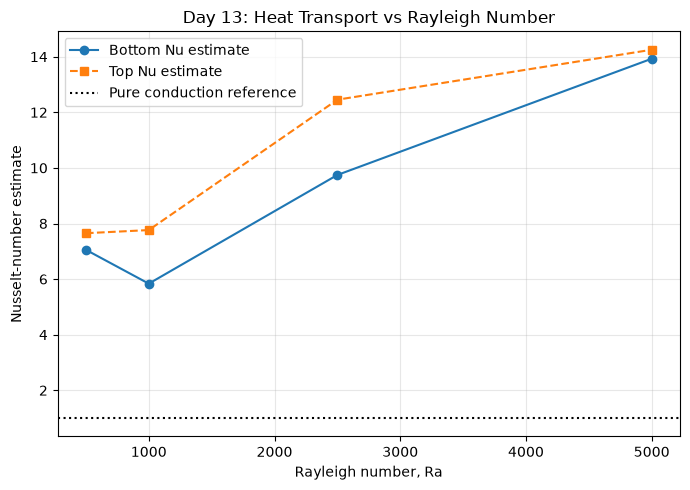


EXPLORATORY POWER-LAW FIT
Nu = C * Ra^beta
Estimated beta = 0.331585661238196
Estimated C = 0.7517596426971191


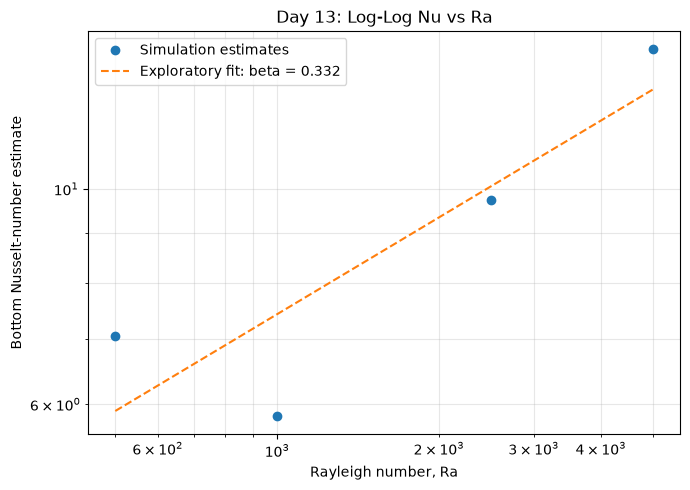

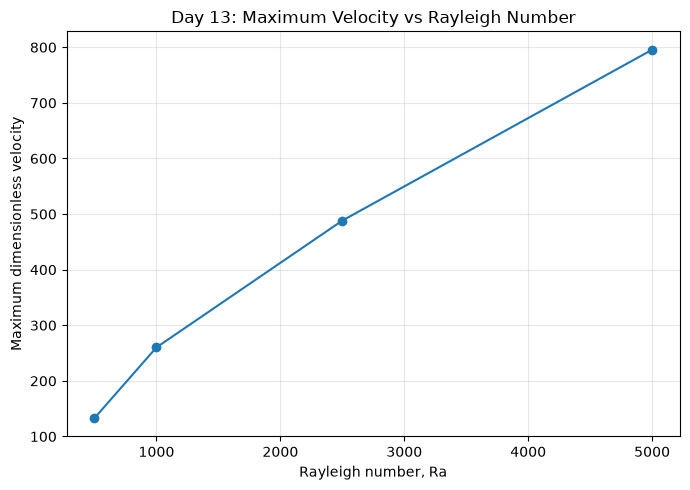

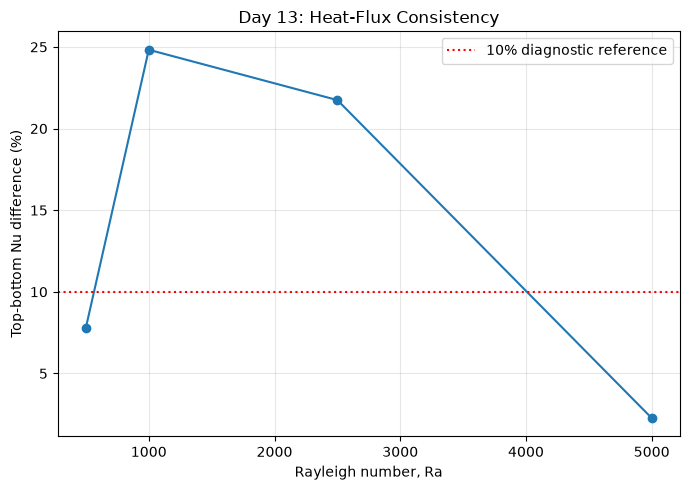


DAY 13 COMPLETED
Output folder: C:\Users\athil\OneDrive\Desktop\day13_Ra_Nu_analysis
Files:
1. day13_analysis_table.csv
2. day13_Nu_vs_Ra.png
3. day13_loglog_fit.png
4. day13_velocity_vs_Ra.png
5. day13_Nu_mismatch.png
6. day13_report.txt


In [1]:
"""
DAY 13: RAYLEIGH NUMBER VS NUSSELT NUMBER

Project:
2-D Numerical Modelling of Thermal Convection
in the Earth's Mantle

Tasks:
1. Read the simulation summary.
2. Compare Nusselt number with Rayleigh number.
3. Plot maximum velocity versus Rayleigh number.
4. Fit an exploratory power law, if possible.
5. Save a CSV analysis table and plots.

Required:
pip install numpy matplotlib
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. SETTINGS
# ============================================================

OUTPUT_DIR = Path("day13_Ra_Nu_analysis")
OUTPUT_DIR.mkdir(exist_ok=True)

print("DAY 13: RAYLEIGH NUMBER AND HEAT TRANSPORT")


# ============================================================
# 2. FIND THE SIMULATION SUMMARY
# ============================================================

possible_files = []

for folder in Path(".").glob("combined_mantle_results*"):
    candidate = folder / "combined_summary.csv"

    if candidate.exists():
        possible_files.append(candidate)

# Select the most recently modified summary.
if not possible_files:
    raise FileNotFoundError(
        "Could not find combined_summary.csv.\n"
        "Run your combined mantle convection program first, "
        "then run this script in the same working directory."
    )

summary_file = max(
    possible_files,
    key=lambda file: file.stat().st_mtime
)

print("Reading:", summary_file.resolve())


# ============================================================
# 3. READ THE CSV FILE
# ============================================================

with open(summary_file, "r", newline="", encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)
    data = list(reader)

if not data:
    raise ValueError("The summary CSV contains no data rows.")


def get_number(row, possible_names):
    """Read the first available numeric column name."""

    for name in possible_names:
        if name in row and row[name] not in ("", None):
            try:
                value = float(row[name])

                if np.isfinite(value):
                    return value

            except (ValueError, TypeError):
                pass

    return np.nan


records = []

for row in data:

    ra = get_number(row, ["Ra", "Rayleigh_number"])
    nu_bottom = get_number(
        row, ["Nu_bottom", "nu_bottom"]
    )
    nu_top = get_number(
        row, ["Nu_top", "nu_top"]
    )
    speed = get_number(
        row, ["max_speed", "max_speed_final", "maximum_velocity"]
    )
    mismatch = get_number(
        row, ["Nu_mismatch_percent", "Nu_mismatch"]
    )

    if np.isfinite(ra):
        records.append({
            "Ra": ra,
            "Nu_bottom": nu_bottom,
            "Nu_top": nu_top,
            "max_speed": speed,
            "Nu_mismatch_percent": mismatch
        })

records.sort(key=lambda item: item["Ra"])

if len(records) < 2:
    raise ValueError(
        "At least two distinct Rayleigh-number results are needed "
        "for comparison. Check combined_summary.csv."
    )

# Remove duplicate Rayleigh numbers so each Ra contributes once.
unique_records = {}

for record in records:
    unique_records[record["Ra"]] = record

records = [
    unique_records[ra]
    for ra in sorted(unique_records)
]

ra = np.array([r["Ra"] for r in records])
nu_bottom = np.array([r["Nu_bottom"] for r in records])
nu_top = np.array([r["Nu_top"] for r in records])
speed = np.array([r["max_speed"] for r in records])
mismatch = np.array([
    r["Nu_mismatch_percent"] for r in records
])

print("\nData loaded successfully.")
print("Number of unique Rayleigh numbers:", len(ra))


# ============================================================
# 4. PRINT A SUMMARY TABLE
# ============================================================

print("\nRESULTS")
print("-" * 76)
print(
    f"{'Ra':>10} {'Nu bottom':>14} {'Nu top':>14} "
    f"{'Max speed':>14} {'Mismatch %':>14}"
)
print("-" * 76)

for i in range(len(ra)):

    print(
        f"{ra[i]:10.2f} "
        f"{nu_bottom[i]:14.6f} "
        f"{nu_top[i]:14.6f} "
        f"{speed[i]:14.6f} "
        f"{mismatch[i]:14.3f}"
    )


# ============================================================
# 5. SAVE CLEANED ANALYSIS TABLE
# ============================================================

analysis_file = OUTPUT_DIR / "day13_analysis_table.csv"

with open(
    analysis_file, "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "Ra",
            "Nu_bottom",
            "Nu_top",
            "max_speed",
            "Nu_mismatch_percent"
        ]
    )

    writer.writeheader()

    for record in records:
        writer.writerow(record)

print("\nSaved analysis table:", analysis_file)


# ============================================================
# 6. NUSSELT NUMBER VS RAYLEIGH NUMBER
# ============================================================

valid_bottom = (
    np.isfinite(nu_bottom)
    & (nu_bottom > 0)
)

valid_top = (
    np.isfinite(nu_top)
    & (nu_top > 0)
)

plt.figure(figsize=(7, 5))

if np.any(valid_bottom):
    plt.plot(
        ra[valid_bottom],
        nu_bottom[valid_bottom],
        "o-",
        label="Bottom Nu estimate"
    )

if np.any(valid_top):
    plt.plot(
        ra[valid_top],
        nu_top[valid_top],
        "s--",
        label="Top Nu estimate"
    )

plt.axhline(
    1,
    color="black",
    linestyle=":",
    label="Pure conduction reference"
)

plt.xlabel("Rayleigh number, Ra")
plt.ylabel("Nusselt-number estimate")
plt.title("Day 13: Heat Transport vs Rayleigh Number")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day13_Nu_vs_Ra.png",
    dpi=180
)

plt.show()


# ============================================================
# 7. LOG-LOG PLOT AND EXPLORATORY POWER-LAW FIT
# ============================================================

valid_fit = (
    np.isfinite(ra)
    & np.isfinite(nu_bottom)
    & (ra > 0)
    & (nu_bottom > 0)
)

ra_fit = ra[valid_fit]
nu_fit = nu_bottom[valid_fit]

fit_slope = np.nan
fit_intercept = np.nan

plt.figure(figsize=(7, 5))

plt.loglog(
    ra_fit,
    nu_fit,
    "o",
    label="Simulation estimates"
)

if len(ra_fit) >= 2 and len(np.unique(ra_fit)) >= 2:

    log_ra = np.log10(ra_fit)
    log_nu = np.log10(nu_fit)

    fit_slope, fit_intercept = np.polyfit(
        log_ra, log_nu, 1
    )

    fitted_nu = 10**(
        fit_intercept + fit_slope*log_ra
    )

    order = np.argsort(ra_fit)

    plt.loglog(
        ra_fit[order],
        fitted_nu[order],
        "--",
        label=f"Exploratory fit: beta = {fit_slope:.3f}"
    )

    print("\nEXPLORATORY POWER-LAW FIT")
    print("Nu = C * Ra^beta")
    print("Estimated beta =", fit_slope)
    print("Estimated C =", 10**fit_intercept)

else:
    print(
        "\nNot enough positive Nu values to calculate "
        "a log-log fit."
    )

plt.xlabel("Rayleigh number, Ra")
plt.ylabel("Bottom Nusselt-number estimate")
plt.title("Day 13: Log-Log Nu vs Ra")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day13_loglog_fit.png",
    dpi=180
)

plt.show()


# ============================================================
# 8. MAXIMUM VELOCITY VS RAYLEIGH NUMBER
# ============================================================

valid_speed = np.isfinite(speed)

plt.figure(figsize=(7, 5))

plt.plot(
    ra[valid_speed],
    speed[valid_speed],
    "o-"
)

plt.xlabel("Rayleigh number, Ra")
plt.ylabel("Maximum dimensionless velocity")
plt.title("Day 13: Maximum Velocity vs Rayleigh Number")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day13_velocity_vs_Ra.png",
    dpi=180
)

plt.show()


# ============================================================
# 9. NUSSELT MISMATCH VS RAYLEIGH NUMBER
# ============================================================

valid_mismatch = np.isfinite(mismatch)

plt.figure(figsize=(7, 5))

plt.plot(
    ra[valid_mismatch],
    mismatch[valid_mismatch],
    "o-"
)

plt.axhline(
    10,
    color="red",
    linestyle=":",
    label="10% diagnostic reference"
)

plt.xlabel("Rayleigh number, Ra")
plt.ylabel("Top-bottom Nu difference (%)")
plt.title("Day 13: Heat-Flux Consistency")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day13_Nu_mismatch.png",
    dpi=180
)

plt.show()


# ============================================================
# 10. SAVE INTERPRETATION REPORT
# ============================================================

report_file = OUTPUT_DIR / "day13_report.txt"

with open(report_file, "w", encoding="utf-8") as f:

    f.write("DAY 13: RAYLEIGH NUMBER AND NUSSELT NUMBER\n")
    f.write("=" * 48 + "\n\n")

    f.write(f"Input file: {summary_file}\n")
    f.write(f"Number of unique Ra values: {len(ra)}\n\n")

    f.write("Exploratory power-law analysis:\n")

    if np.isfinite(fit_slope):
        f.write(f"Estimated beta = {fit_slope:.6f}\n")
        f.write(f"Estimated C = {10**fit_intercept:.6f}\n")
    else:
        f.write("No fit could be calculated.\n")

    f.write("\nImportant limitations:\n")
    f.write(
        "- The power-law fit is descriptive, not proof of a "
        "physical scaling law.\n"
    )
    f.write(
        "- Nusselt estimates may represent transient states.\n"
    )
    f.write(
        "- Check grid and time convergence before interpreting "
        "the fitted exponent physically.\n"
    )
    f.write(
        "- A large top-bottom heat-flux mismatch indicates "
        "that steady-state interpretation needs caution.\n"
    )

print("\n" + "=" * 60)
print("DAY 13 COMPLETED")
print("=" * 60)
print("Output folder:", OUTPUT_DIR.resolve())
print("Files:")
print("1. day13_analysis_table.csv")
print("2. day13_Nu_vs_Ra.png")
print("3. day13_loglog_fit.png")
print("4. day13_velocity_vs_Ra.png")
print("5. day13_Nu_mismatch.png")
print("6. day13_report.txt")